# Part One: Signal in the Static
Pipeline: load FITS -> plot raw frames -> median reference -> difference images -> noise-based detection -> track the moving source -> trajectory + SNR.

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from scipy.stats import f as f_dist, norm

TEAM = "llcd"
DATA = Path("dataset/Task1")       # folder holding frame_01.fits ... frame_20.fits
OUT = Path(f"{TEAM}_FITS_outputs")

K_SIGMA = 5     # detection threshold, in noise sigmas
SMOOTH = 1.0    # Gaussian smoothing (px) before thresholding (boosts faint point sources); 0 = off
MIN_AREA = 2    # minimum connected pixels above threshold
TOL = 2.0       # px: max distance between a detection and the predicted track position
MIN_FRAC = 0.5  # "consistent" = the source must be detected in at least this fraction of the frames
MIN_MOTION = 3 * TOL   # px: detections on a track must spread at least this far (else it is a stationary residual)

for sub in ("raw_frames", "difference_images"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

## 1. Load frames
Frames are ordered by the `FRAME` header keyword, not by file name.

In [2]:
data = []
for f in sorted(DATA.glob("frame_*.fits")):
    with fits.open(f) as hdul:
        hdr = hdul[0].header
        data.append((hdr["FRAME"], hdul[0].data.astype(float), np.datetime64(hdr["DATE-OBS"])))
data.sort(key=lambda t: t[0])
nums = np.array([t[0] for t in data])
stack = np.array([t[1] for t in data])            # shape (n_frames, ny, nx)
gaps = np.diff([t[2] for t in data]) / np.timedelta64(1, "s")      # seconds between frames, from DATE-OBS
assert (np.diff(nums) == 1).all(), f"frame numbers are not consecutive: {nums}"
print(f"{len(nums)} frames, image size {stack.shape[1:]}, NaN pixels: {np.isnan(stack).sum()}, "
      f"time between frames: {gaps.min():.0f}-{gaps.max():.0f} s")


def plot_image(img, title, path, cmap="gray", vmin=None, vmax=None, marker=None):
    """Image with labelled axes and a colorbar, saved to `path`."""
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set(title=title, xlabel="x (pixel)", ylabel="y (pixel)")
    fig.colorbar(im, ax=ax, label="Signal (ADU)")
    if marker is not None:
        ax.autoscale(False)
        ax.plot(*marker, "o", mfc="none", mec="red", ms=16)
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.close(fig)

20 frames, image size (200, 200), NaN pixels: 0, time between frames: 90-90 s


## 2. Plot every raw frame
One shared contrast stretch (1st to 99.5th percentile of all pixels) so frames are directly comparable.

In [3]:
lo, hi = np.nanpercentile(stack, [1, 99.5])
for n, img in zip(nums, stack):
    plot_image(img, f"Raw frame {n:02d}", OUT / "raw_frames" / f"frame_{n:02d}.png", vmin=lo, vmax=hi)

## 3. Median reference and difference images
Stars and background sit at the same pixels in every frame, so they survive in the median. The moving source
is at a different pixel in each frame, so the median rejects it. Subtracting the reference cancels everything
static and leaves the moving source (plus noise).

In [4]:
ref = np.nanmedian(stack, axis=0)
plot_image(ref, "Median reference image", OUT / "median_reference.png", vmin=lo, vmax=hi)

diff = np.nan_to_num(stack - ref)
diff -= np.median(diff, axis=(1, 2), keepdims=True)     # remove any per-frame background offset

## 4. Noise level and candidate detection
Noise = sigma-clipped standard deviation of each difference image (clipping stops the source and star residuals
from inflating it). Candidates = connected pixels above `K_SIGMA` x noise in the lightly smoothed difference image.

In [5]:
smooth = ndi.gaussian_filter(diff, sigma=(0, SMOOTH, SMOOTH)) if SMOOTH else diff
noise = np.array([sigma_clipped_stats(d, sigma=3)[2] for d in diff])      # raw difference images
noise_s = np.array([sigma_clipped_stats(d, sigma=3)[2] for d in smooth])  # smoothed difference images

rows = []                       # frame_index, x, y, peak (ADU in raw difference image)
for i, s in enumerate(smooth):
    lab, n = ndi.label(s > K_SIGMA * noise_s[i])
    if n == 0:
        continue
    idx = np.arange(1, n + 1)
    big = ndi.sum(lab > 0, lab, idx) >= MIN_AREA
    cy, cx = np.array(ndi.center_of_mass(s, lab, idx)).T
    peak = np.atleast_1d(ndi.maximum(diff[i], lab, idx))
    rows += [(i, x, y, p) for x, y, p, ok in zip(cx, cy, peak, big) if ok]
cands = np.array(rows)
print(f"{len(cands)} candidate detections over {len(nums)} frames")

23 candidate detections over 20 frames


## 5. Separate the moving source from spurious detections
1. **Static residuals** (imperfect star subtraction): a detection that recurs at the same spot in more than
   half the frames cannot be a moving object, so it is dropped.
2. **Moving source**: search all pairs of remaining detections for the constant-velocity line that is matched
   (within `TOL` px) by detections in the most frames. Isolated noise peaks do not line up, so they never score,
   and tracks whose detections barely spread (`MIN_MOTION`) are rejected because they are stationary residuals.

In [6]:
xy, fr = cands[:, 1:3], cands[:, 0].astype(int)
n_seen = np.array([len(set(fr[j])) for j in cKDTree(xy).query_ball_point(xy, TOL)])
static = n_seen > 0.5 * len(nums)
mov = cands[~static]
mfr = mov[:, 0].astype(int)


def predict(a, b, frames):
    """Position at `frames` of the line through detections a and b."""
    (fa, xa, ya), (fb, xb, yb) = a[:3], b[:3]
    k = (frames - fa) / (fb - fa)
    return np.c_[xa + k * (xb - xa), ya + k * (yb - ya)]


best, best_hits = None, 0
for a, b in combinations(range(len(mov)), 2):
    if mov[b, 0] <= mov[a, 0]:
        continue
    hit = np.hypot(*(mov[:, 1:3] - predict(mov[a], mov[b], mov[:, 0])).T) < TOL
    moved = np.ptp(mov[hit, 1:3], axis=0).max()     # stationary residuals never spread beyond ~TOL
    if moved >= MIN_MOTION and len(set(mfr[hit])) > best_hits:
        best, best_hits = hit, len(set(mfr[hit]))
assert best_hits >= MIN_FRAC * len(nums), \
    f"no consistent moving source: best track has only {best_hits}/{len(nums)} detections (lower K_SIGMA or MIN_FRAC to relax)"


def fit_line(sel):
    """Keep the brightest detection per frame, then least-squares line x(t), y(t)."""
    per_frame = {}
    for r in sel:
        if int(r[0]) not in per_frame or r[3] > per_frame[int(r[0])][3]:
            per_frame[int(r[0])] = r
    trk = np.array([per_frame[k] for k in sorted(per_frame)])
    return trk, np.polyfit(trk[:, 0], trk[:, 1], 1), np.polyfit(trk[:, 0], trk[:, 2], 1)


t_all = np.arange(len(nums))
trk, px, py = fit_line(mov[best])
for _ in range(2):      # re-gate every detection against the fitted line, then refit
    pos = np.c_[np.polyval(px, t_all), np.polyval(py, t_all)]
    trk, px, py = fit_line(mov[np.hypot(*(mov[:, 1:3] - pos[mfr]).T) < TOL])
pos = np.c_[np.polyval(px, t_all), np.polyval(py, t_all)]      # source position in every frame
detected = np.isin(t_all, trk[:, 0])

# Straight line or curve? F-test: does a quadratic path explain the detections significantly better?
tt = trk[:, 0]


def rms(deg):
    """RMS distance (px) between the measured centroids and a polynomial path of this degree."""
    r = [np.polyval(np.polyfit(tt, trk[:, k], deg), tt) - trk[:, k] for k in (1, 2)]
    return np.sqrt(np.mean(r[0] ** 2 + r[1] ** 2))


dof = 2 * len(tt) - 6
p_quad = f_dist.sf(((rms(1) ** 2 - rms(2) ** 2) / 2) / (rms(2) ** 2 / dof), 2, dof)
deg = 2 if p_quad < 0.01 else 1
cx, cy = np.polyfit(tt, trk[:, 1], deg), np.polyfit(tt, trk[:, 2], deg)
pos = np.c_[np.polyval(cx, t_all), np.polyval(cy, t_all)]      # final model position in every frame
meas = np.full((len(nums), 2), np.nan)
meas[tt.astype(int)] = trk[:, 1:3]                              # measured centroids (NaN where not detected)
print(f"path model: {'quadratic (curved)' if deg == 2 else 'linear'} | RMS residual {rms(1):.2f} px (line) vs "
      f"{rms(2):.2f} px (quadratic), F-test p = {p_quad:.2g}")
print(f"static residual detections: {static.sum()} | moving-source detections: {len(trk)} | "
      f"other (isolated noise peaks): {len(mov) - len(trk)}")

path model: quadratic (curved) | RMS residual 0.76 px (line) vs 0.27 px (quadratic), F-test p = 6.5e-16
static residual detections: 0 | moving-source detections: 20 | other (isolated noise peaks): 3


## 6. Difference images (red circle = tracked source)

In [7]:
v = 5 * noise.mean()
for n, d, p in zip(nums, diff, pos):
    plot_image(d, f"Difference image {n:02d}", OUT / "difference_images" / f"diff_{n:02d}.png",
               vmin=-v, vmax=v, marker=p)

## 7. Trajectory plot

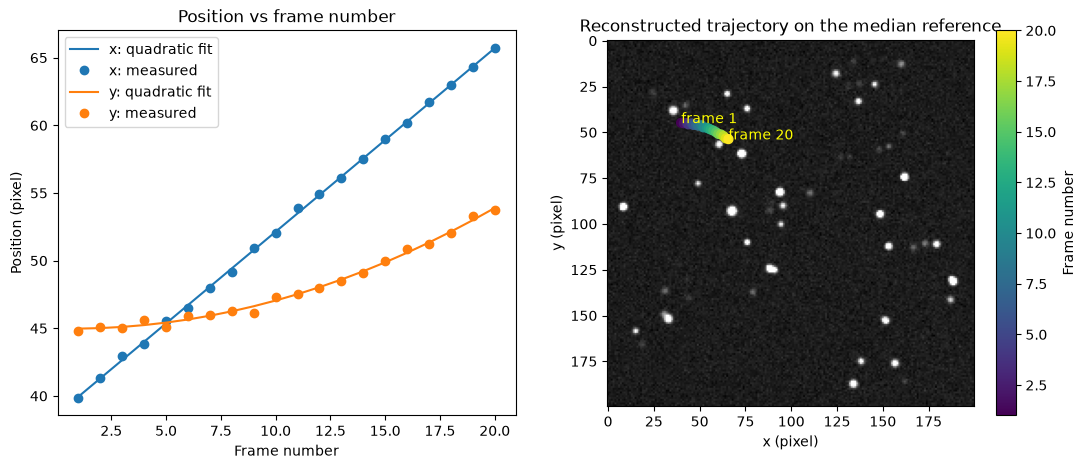

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for k, (name, c) in enumerate((("x", "tab:blue"), ("y", "tab:orange"))):
    a1.plot(nums, pos[:, k], "-", c=c, label=f"{name}: {'quadratic' if deg == 2 else 'linear'} fit")
    a1.plot(nums, meas[:, k], "o", c=c, label=f"{name}: measured")
a1.set(xlabel="Frame number", ylabel="Position (pixel)", title="Position vs frame number")
a1.legend()

a2.imshow(ref, cmap="gray", vmin=lo, vmax=hi)
a2.autoscale(False)
a2.plot(*pos.T, "-", c="red", lw=1)
sc = a2.scatter(*meas[detected].T, c=nums[detected], cmap="viridis", s=40, zorder=3)
a2.annotate(f"frame {nums[0]}", pos[0], color="yellow")
a2.annotate(f"frame {nums[-1]}", pos[-1], color="yellow")
fig.colorbar(sc, ax=a2, label="Frame number")
a2.set(xlabel="x (pixel)", ylabel="y (pixel)", title="Reconstructed trajectory on the median reference")
fig.savefig(f"{TEAM}_trajectory.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Numbers, and the written report (`llcd_task1_solution.md` is generated from these values)

In [9]:
def local_peak(img, x, y, r=2):
    """Maximum of `img` in a (2r+1)-pixel box around (x, y); NaN if the box is off the image."""
    x0, y0 = int(round(x)), int(round(y))
    sub = img[max(y0 - r, 0): y0 + r + 1, max(x0 - r, 0): x0 + r + 1]
    return sub.max() if sub.size else np.nan


peak = np.array([local_peak(d, *p) for d, p in zip(diff, pos)])
peak_s = np.array([local_peak(s, *p) for s, p in zip(smooth, pos)])
table = pd.DataFrame({"frame": nums, "x_measured": meas[:, 0], "y_measured": meas[:, 1], "x_model": pos[:, 0],
                      "y_model": pos[:, 1], "detected": detected, "peak_ADU": peak, "SNR": peak / noise,
                      "SNR_smoothed": peak_s / noise_s})
print(table.round(2).to_string(index=False))

vel = np.c_[np.polyval(np.polyder(cx), t_all), np.polyval(np.polyder(cy), t_all)]    # px/frame in every frame
speed, path, gap = np.hypot(*vel.T), np.hypot(*np.diff(pos, axis=0).T).sum(), np.median(gaps)
angle = np.degrees(np.arctan2(*(pos[-1] - pos[0])[::-1]))
d = table[table.detected]
false_px = diff[0].size * len(nums) * norm.sf(K_SIGMA)
summary = [
    f"Path model: {'quadratic (curved)' if deg == 2 else 'linear'}; RMS residual {rms(1):.2f} px (line) vs {rms(2):.2f} px "
    f"(quadratic), F-test p = {p_quad:.2g}",
    f"Noise in difference images: mean {noise.mean():.2f} ADU (range {noise.min():.2f}-{noise.max():.2f}); after smoothing {noise_s.mean():.2f} ADU",
    f"Source detected in {detected.sum()}/{len(nums)} frames; speed {speed[0]:.2f} px/frame (frame {nums[0]}) -> {speed[-1]:.2f} "
    f"(frame {nums[-1]}); path {path:.0f} px; overall direction {angle:.0f} deg (image axes, y points down)",
    f"Signal (median over detected frames): peak {d.peak_ADU.median():.1f} ADU -> SNR {d.SNR.median():.1f} (raw), "
    f"{d.SNR_smoothed.median():.1f} (smoothed); minimum raw SNR {d.SNR.min():.1f}",
    f"Expected false pixels at {K_SIGMA} sigma if noise were Gaussian: {false_px:.2f} over all frames"]
print("\n" + "\n".join(summary))


def md(df):
    return "\n".join(["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
                     + ["| " + " | ".join(map(str, r)) + " |" for r in df.round(2).itertuples(index=False)])


shape = ("a smooth, slightly curved path: a quadratic fits the measured centroids significantly better than a straight line "
         f"(F-test p = {p_quad:.2g}; RMS residual {rms(2):.2f} px vs {rms(1):.2f} px), so the apparent velocity changes slowly "
         f"from {speed[0]:.2f} to {speed[-1]:.2f} px/frame" if deg == 2 else
         f"a straight path at nearly constant speed ({speed[0]:.2f} px/frame); a quadratic is not significantly better (p = {p_quad:.2g})")
rate = f", i.e. about {speed.mean() / (gap / 60):.2f} px per minute at the {gap:.0f} s frame spacing" if gap > 0 else ""
report = f"""# Task 1: Signal in the Static (team {TEAM})

All figures and numbers below are produced by `{TEAM}_notebook_FITS.ipynb`.

## 1. Raw frames
There are {len(nums)} FITS frames of {stack.shape[2]} x {stack.shape[1]} pixels (field "{hdr.get('OBJECT', '?')}", {hdr.get('EXPTIME', '?')} s exposures, signal in ADU), ordered by the `FRAME` header keyword. `DATE-OBS` gives {gaps.min():.0f}-{gaps.max():.0f} s between consecutive frames. The headers contain no world-coordinate information, so there is no pixel scale: positions and speeds are in pixels. Every frame is plotted with labelled axes and a colorbar in `{OUT}/raw_frames/`, all with one shared contrast stretch (1st-99.5th percentile) so they can be compared directly.

![Raw frame 1]({OUT}/raw_frames/frame_01.png)

## 2. Median reference and difference images
The reference image is the per-pixel median of all {len(nums)} frames (`{OUT}/median_reference.png`). Stars and background sit on the same pixels in every frame, so they pass through the median unchanged, while the moving source occupies any one pixel in only a few frames, so the median rejects it. Subtracting the reference from each frame (and removing the small per-frame background offset) cancels everything static and leaves only what changed in that frame: the moving source as a faint positive blob, plus noise and small residuals around the brightest stars. The difference images are in `{OUT}/difference_images/`, with the tracked source circled in red.

![Median reference]({OUT}/median_reference.png)
![Difference image {nums[len(nums) // 2]}]({OUT}/difference_images/diff_{nums[len(nums) // 2]:02d}.png)

## 3. Detecting the moving source
The noise of each difference image is its sigma-clipped standard deviation (mean {noise.mean():.2f} ADU). Each difference image is smoothed with a {SMOOTH:g}-pixel Gaussian, which suits a point source and lowers the noise to {noise_s.mean():.2f} ADU, and every group of at least {MIN_AREA} connected pixels above {K_SIGMA} sigma is a candidate. This gives {len(cands)} candidates. They are separated as follows:
- **{static.sum()} static residuals** (imperfectly subtracted stars): a detection that recurs within {TOL:g} px of the same spot in more than half of the frames cannot be a moving object.
- **{len(mov) - len(trk)} other candidates** (isolated noise peaks): they do not line up with each other or with the track.
- **{len(trk)} detections that form one track**: the constant-velocity line matched (within {TOL:g} px) by detections in the most frames, whose detections spread over at least {MIN_MOTION:g} px (a stationary residual cannot do that). The source is detected in {detected.sum()} of {len(nums)} frames, one detection per frame.

## 4. Trajectory
Measured centroids and the fitted path (`{TEAM}_trajectory.png`):

![Trajectory]({TEAM}_trajectory.png)

{md(table[["frame", "x_measured", "y_measured", "x_model", "y_model"]])}

The source follows {shape}. Over the {len(nums)} frames it travels {path:.0f} px (overall direction {angle:.0f} degrees from the +x axis, y pointing down){rate}.

**What kind of object?** Stars and nebulosity do not move and noise does not move coherently, so a source that shifts smoothly in one direction over {len(nums)} frames is a real object whose position relative to the background stars changes. That is the signature of a foreground body: in a real survey a solar-system minor body (asteroid or comet), another nearby object, or an artificial one such as a spacecraft.{" A slowly changing apparent velocity is what a body on a gravity-curved orbit shows, or any body seen from a moving observer." if deg == 2 else ""} Distance, size and physical speed cannot be obtained because the headers have no pixel scale.

## 5. Noise, signal strength, reliability and limitations
- **Noise:** {noise.mean():.2f} ADU per pixel in the difference images (frame-to-frame range {noise.min():.2f}-{noise.max():.2f} ADU); {noise_s.mean():.2f} ADU after smoothing.
- **Signal:** the source peaks at {d.peak_ADU.median():.1f} ADU (median over detected frames), which is {d.SNR.median():.1f} sigma in the raw difference images (weakest frame {d.SNR.min():.1f} sigma) and {d.SNR_smoothed.median():.1f} sigma in the smoothed ones.
- **Reliability:** with Gaussian noise only {false_px:.2f} pixels over all frames would exceed {K_SIGMA} sigma by chance. The source is found in {detected.sum()} of {len(nums)} frames and the centroids follow one smooth path to {rms(deg):.2f} px RMS, so a chance alignment of noise peaks is extremely unlikely.
- **Limitations:** (1) In single raw frames the source is only about {d.SNR.median():.0f} sigma, so the detection relies on smoothing and on consistency across frames, not on any one frame. (2) The noise is not perfectly Gaussian: near bright stars the subtraction leaves larger residuals, so the global sigma understates the local noise there. (3) The path model is a low-order polynomial; the measured centroids scatter by {rms(deg):.2f} px RMS around it. (4) A source that stays within {TOL:g} px for more than half of the frames would be absorbed into the median and removed as static. (5) Only the single best track is searched for; a second, fainter mover would need another pass. (6) Without a pixel scale, no physical size, distance or speed can be derived.
"""
Path(f"{TEAM}_task1_solution.md").write_text(report, encoding="utf-8")
print(f"\nwrote {TEAM}_task1_solution.md")

 frame  x_measured  y_measured  x_model  y_model  detected  peak_ADU  SNR  SNR_smoothed
     1       39.85       44.81    39.95    44.97      True     17.69 6.13         10.55
     2       41.36       45.08    41.30    45.01      True     18.09 6.27          9.95
     3       42.92       44.99    42.65    45.10      True     16.32 5.65          9.67
     4       43.85       45.65    44.01    45.24      True     14.22 4.92          8.34
     5       45.53       45.13    45.36    45.42      True     15.44 5.33         10.08
     6       46.52       45.94    46.72    45.65      True     13.15 4.52          7.90
     7       48.00       45.98    48.07    45.93      True      9.79 3.39          7.67
     8       49.17       46.31    49.43    46.26      True     16.73 5.81         10.51
     9       50.90       46.14    50.78    46.63      True     12.29 4.20          8.16
    10       52.02       47.29    52.14    47.05      True     13.41 4.61          8.58
    11       53.90       47.50  